# libraries

first we will import the necessary libraries and load the dataset. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("heart.csv")

# The problem statement

This heart disease dataset contains 76 attributes, including the predicted attribute, but all published experiments refer to using a subset of 14 of them. The "target" field refers to the presence of heart disease in the patient. It is integer valued 0 = no disease and 1 = disease.

The problem is to predict the presence of heart disease in the patient. 

**Attribute Information:**
1. **age**
2. **sex** (1 = male, 0 = female)
3. **chest pain type** (value types : 4 degrees)
4. **resting blood pressure** (measured in mm Hg)
5. **serum cholesterol in mg/dl** (measured in mg/dl)
6. **fasting blood sugar** (value types : true (>120 mg/dl) or false)
7. **resting electrocardiographic results** (value types : 3 degrees)
8. **maximum heart rate achieved** (measured in bpm)
9. **exercise induced angina** (value types : yes, no)
10. **oldpeak** (ST depression induced by exercise relative to rest)
11. **the slope of the peak exercise ST segment** (value types :  3 degrees)
12. **number of major vessels** (0-3) colored by fluoroscopy
13. **thal**: (value types : normal, fixed defect, reversable defect)


# Data Exploration

### lets understand the dataset by
- Learning about the features (columns) and their types
- Their current format VS the format they should be in
- The number of unique values in each feature 
- Visualizing the data to see if there are any patterns or relationships between the features and the target variable.


In [3]:
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
6,58,1,0,114,318,0,2,140,0,4.4,0,3,1,0
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0
8,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
9,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0


- Data types of features

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


For the categorical data (mentioned in the attribute information) we will check the values in each of them to predict and study what they represent 

In [5]:
print("Sex:", df['sex'].unique())
print("Fasting Blood Sugar:", df['fbs'].unique())
print("Exercise Induced Angina:", df['exang'].unique())
print("Chest Pain Type:", df['cp'].unique())
print("Resting ECG:", df['restecg'].unique())
print("Slope:", df['slope'].unique())
print("Thal:", df['thal'].unique())

Sex: [1 0]
Fasting Blood Sugar: [0 1]
Exercise Induced Angina: [0 1]
Chest Pain Type: [0 1 2 3]
Resting ECG: [1 0 2]
Slope: [2 0 1]
Thal: [3 2 1 0]


Looking at the raw data, several columns are stored as integers but they don't actually represent quantities — they represent categories. If we leave them as-is, the model (and any scaling we might apply) would incorrectly treat them as if there's a meaningful numeric distance between the values.

**Binary categorical features** — already 0/1, just need to be explicitly treated as categorical rather than numeric:
- `sex` (0 = female, 1 = male)
- `fbs` (0 = false, 1 = true)
- `exang` (0 = no, 1 = yes)

These don't need any transformation beyond recognizing them as flags, not magnitudes.

Since they are already binary, we can leave them as-is, Mathematically if the model was to choose a threshold it would be of 0.5, separating the two classes like this {0} and {1}, properly without the need for additional transformation or one-hot encoding.

**Multi-class nominal features** — these have 3+ categories with no meaningful order between them, so treating them as plain integers would wrongly imply that, say, `thal = 2` is somehow "between" `thal = 1` and `thal = 3`:
- `cp` (chest pain type)
- `restecg` (resting ECG results)
- `slope` (slope of the peak exercise ST segment)
- `thal` (thalassemia type)

These are all "types" of something, not quantities, its like saying 1 is apple, 2 is banana, and 3 is cherry — there's no inherent order to those fruits, they're just flags for different categories not a measurment or a ranking.

We'll one-hot encode this second group later in the notebook, turning each into a set of binary columns — one per category — so the model can treat them as unordered labels rather than ranked numbers.

Now lets explore the dataset to understand its structure and contents. We will check for missing values, data types, and basic statistics of the features.


In [6]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


# Preprocessing the data

## Preprocessing checklist for decision trees :

Decision trees need less preprocessing than most other ML algorithms — but "less" doesn't mean "none." Here's what to actually do, and just as importantly, what you can skip.

### Required

- **Handle missing values.** `sklearn`'s tree implementation can't take `NaN`s directly — check with `df.isnull().sum()` and decide whether to impute or drop. (Note: gradient boosting libraries like XGBoost/LightGBM/CatBoost handle missing values natively — this is a `sklearn` limitation, not a tree limitation in general.)

- **Remove duplicate rows — before splitting, not after.** Check with `df.duplicated().sum()`. If duplicates end up split across train and test, the model gets evaluated on data it already memorized, which quietly inflates your test accuracy.

- **Encode categorical features correctly, based on whether they're ordered:**
  - *Binary features* (e.g. `sex`, `fbs`, `exang`) — already 0/1, no transformation needed.
  - *Nominal features with 3+ unordered categories* (e.g. `cp`, `restecg`, `thal`) — one-hot encode. Leaving them as raw integers implies a false ordering (that category `2` sits "between" `1` and `3`), which forces the tree to spend extra, unnecessary splits just to isolate one category properly.

- **Make sure the target is numeric** (e.g. `0`/`1`, not `"yes"`/`"no"`).

- **Split into train/test *after* the steps above** — this is what makes the rest of the notebook's overfitting-vs-pruning story valid in the first place.

### Not required (and worth knowing *why*, not just memorizing)

- **Feature scaling / normalization** — trees split on raw thresholds (`feature <= value`), not distances or magnitudes, so scale doesn't affect the splits at all.
- **Outlier removal** — trees search for splits by how well they separate classes, not by mean or distance, so a single extreme value rarely wins as a split point. (An unconstrained tree carving out a tiny leaf for one weird row is an overfitting problem, not an outlier problem — pruning handles it.)
- **Fixing skewed distributions (log-transforms, etc.)** — trees only care about the *rank order* of values, not their spread. Any monotonic transform produces identical splits.
- **Handling multicollinearity** — correlated features don't distort a tree's splits the way they distort a linear model's coefficients (though they can make feature importances a bit harder to interpret).

### General data hygiene (not tree-specific, but still worth checking)

- Implausible values that suggest a data-entry issue rather than a genuine outlier (e.g. is `chol = 0` a real reading, or a placeholder for missing data?)
- Class balance on the target — this shapes how you'll interpret accuracy later on

In [7]:
#Checking for missing values
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

**Checking for duplicate rows**

Before splitting the data, we check for duplicate rows using `df.duplicated().sum()`.

This dataset is a wider Kaggle version of a smaller original heart disease dataset, so it's expected to contain repeated records rather than only unique patients. If we don't handle this, the same row can end up in both our training set and our test set later on — the model would then be evaluated on data it has already memorized, making our accuracy look better than it actually is.

To avoid this, we drop duplicates **before** doing the train/test split, not after. This gives us a smaller but fully unique set of patients to work with, and keeps our later evaluation honest.

We will drop these duplicate rows in the next step.

In [8]:
df.duplicated().sum()

np.int64(723)

In [9]:
df.drop_duplicates(inplace= True)

In [10]:
#one hot encoding the categorical variables
df_encoded = pd.get_dummies(df, columns=['cp', 'restecg', 'slope', 'thal'], prefix=['chest_pain_type', 'resting_ecg', 'slope', 'thal'], dtype=int)
df_encoded.info()

# 'prefix' is to rename the new columns to something more meaningful
# 'dtype' is to set the data type of the new columns to integer (0 or 1) instead of (true or false) to make sure the data is numeric

<class 'pandas.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                302 non-null    int64  
 1   sex                302 non-null    int64  
 2   trestbps           302 non-null    int64  
 3   chol               302 non-null    int64  
 4   fbs                302 non-null    int64  
 5   thalach            302 non-null    int64  
 6   exang              302 non-null    int64  
 7   oldpeak            302 non-null    float64
 8   ca                 302 non-null    int64  
 9   target             302 non-null    int64  
 10  chest_pain_type_0  302 non-null    int64  
 11  chest_pain_type_1  302 non-null    int64  
 12  chest_pain_type_2  302 non-null    int64  
 13  chest_pain_type_3  302 non-null    int64  
 14  resting_ecg_0      302 non-null    int64  
 15  resting_ecg_1      302 non-null    int64  
 16  resting_ecg_2      302 non-null    int64  

Now if we notice the difference between the original dataset and the new dataset after dropping duplicates, we can see that the number of rows has decreased. And after the one-hot encoding, the number of columns has increased due to the creation of new binary columns for each category, went from 14 to 20 columns.


Now we are ready to split the dataset into training and testing sets, and then we can proceed to train our decision tree model.


In [38]:

# A function to plot the values of each class found by .value_counts(), and the percentage of every class in each binary feature 
def BinaryBalanceCheck(data) :
    for col in data.columns:
        # Only process binary columns (0 and 1)
        if set(data[col].unique()) == {0, 1}:
            column = data[col].value_counts()
            plt.figure(figsize=(8, 4))
            plt.bar(column.index, column.values)
            plt.xlabel(col)
            plt.ylabel('count')
            plt.title(f'Distribution of {col}')
            plt.show()
            total_rows = data[col].count()
            percentage_c1 = (data[col] == 0).sum()
            percentage_c2 = (data[col] == 1).sum()
            print(f'Distribution of {col}')
            print("The percentage of Class \"False\" :{0: .2f}%".format((percentage_c1 / total_rows) * 100)) 
            print("The percentage of Class \"True\" :{0: .2f}%".format((percentage_c2 / total_rows) * 100))

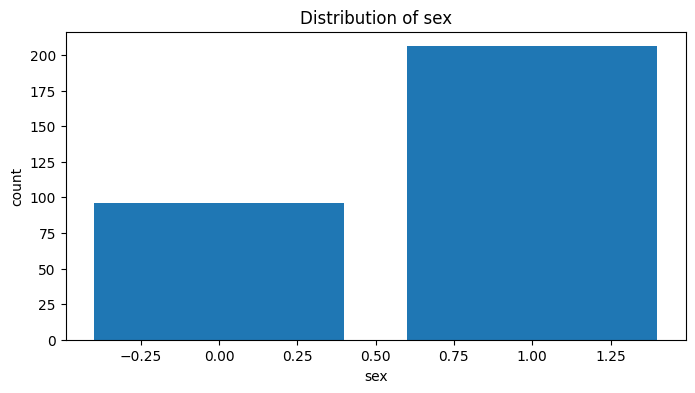

Distribution of sex
The percentage of Class "False" : 31.79%
The percentage of Class "True" : 68.21%


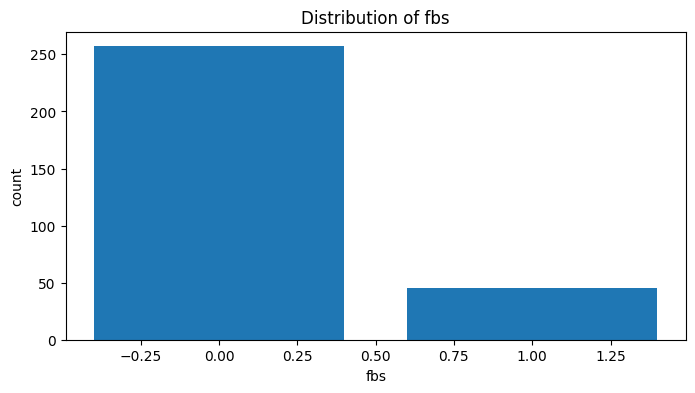

Distribution of fbs
The percentage of Class "False" : 85.10%
The percentage of Class "True" : 14.90%


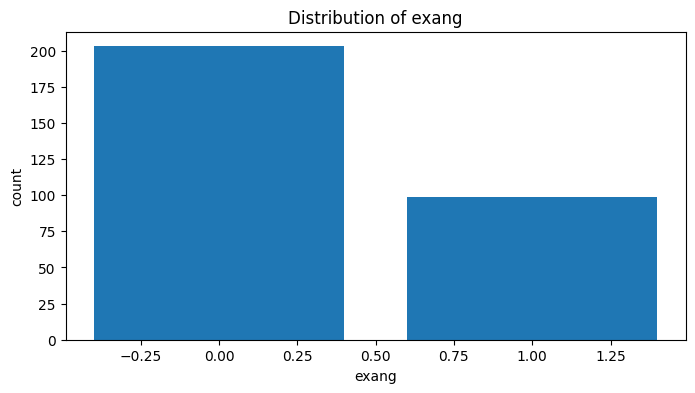

Distribution of exang
The percentage of Class "False" : 67.22%
The percentage of Class "True" : 32.78%


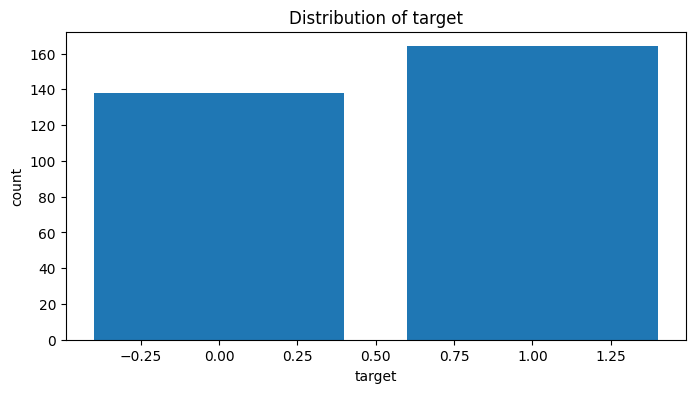

Distribution of target
The percentage of Class "False" : 45.70%
The percentage of Class "True" : 54.30%


In [39]:
BinaryBalanceCheck(df)

The target column is perfectly balanced so we dont need to worry about it,

BUT if you look at fbs you will notice it's very imbalanced, are we going to do anything about it ? 

**No!**, because the imbalance in that feature is actually reality! we only try to fix the imbalanced features if their data represents discrimination or bias unlike the reality 

Most of the people's fasting blood sugar is below 120 mg/dl (false class), so the imbalance in this feature is actually a reflection of reality, and we should not try to fix it.

## Splitting the dataset into training and testing sets

In [11]:
X = df_encoded.drop('target', axis=1)
Y = df_encoded['target']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Model Creation


In [14]:
# using entropy as the criterion for the decision tree classifier
dtree_ent = DecisionTreeClassifier(random_state=0 , criterion='entropy')
dtree_ent.fit(X_train, Y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [15]:
# using gini index as the criterion for the decision tree classifier
dtree_gini = DecisionTreeClassifier(random_state=0 , criterion='gini')
dtree_gini.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [16]:
# making predictions on the training set
y_tr_ent = dtree_ent.predict(X_train)
y_tr_gini = dtree_gini.predict(X_train)

In [17]:
# checking the accuracy score on the training set to ensure that its well trained
print('train test accuracy score with criterion gini index: {0:0.4f}'. format(accuracy_score(Y_train, y_tr_gini)))
print('train test accuracy score with criterion entropy: {0:0.4f}'. format(accuracy_score(Y_train, y_tr_ent)))

train test accuracy score with criterion gini index: 1.0000
train test accuracy score with criterion entropy: 1.0000


In [18]:
# making predictions on the test set
y_pred_ent = dtree_ent.predict(X_test)
y_pred_gini = dtree_gini.predict(X_test)

In [19]:
# final accuracy score on the models using the test set
print('Model accuracy score with criterion gini index: {0:0.4f}'. format(accuracy_score(Y_test, y_pred_gini)))
print('Model accuracy score with criterion entropy: {0:0.4f}'. format(accuracy_score(Y_test, y_pred_ent)))

Model accuracy score with criterion gini index: 0.7049
Model accuracy score with criterion entropy: 0.7869


## analysis and comparison of the performance of decision tree classifier using gini index and entropy as the criterion

Looking at the accuracy scores we notice that the training accuracy score is higher than the testing accuracy score, which indicates that the model is overfitting the training data.

Regarding the performance of entropy and gini compared to each other, we notice that entropy performs much better than gini index in this case (it depends on the dataset). 

**Looking at the trees plotted down below**, we can see that the depth of the trees is different, and the number of nodes is also different.If we calculate, The tree with **entropy** as the criterion has a **depth of 5 and 31 nodes**, while the tree with **gini** index as the criterion has a **depth of 6 and 63 nodes**. This indicates that the tree with gini index is more complex and has more splits, which can lead to overfitting.

We also notice that in entropy tree stops splitting once the entropy reaches 0, and so does the gini tree.

And thats what makes the model **overfit** the training data, It fails to generalize well on unseen data because it has learned the noise in the training data rather than the underlying patterns (the model has **memortized** the training data). the accuracy of the training data doesnt have to be 100% for the model to be considered good, but it should be close to the accuracy of the testing data. 

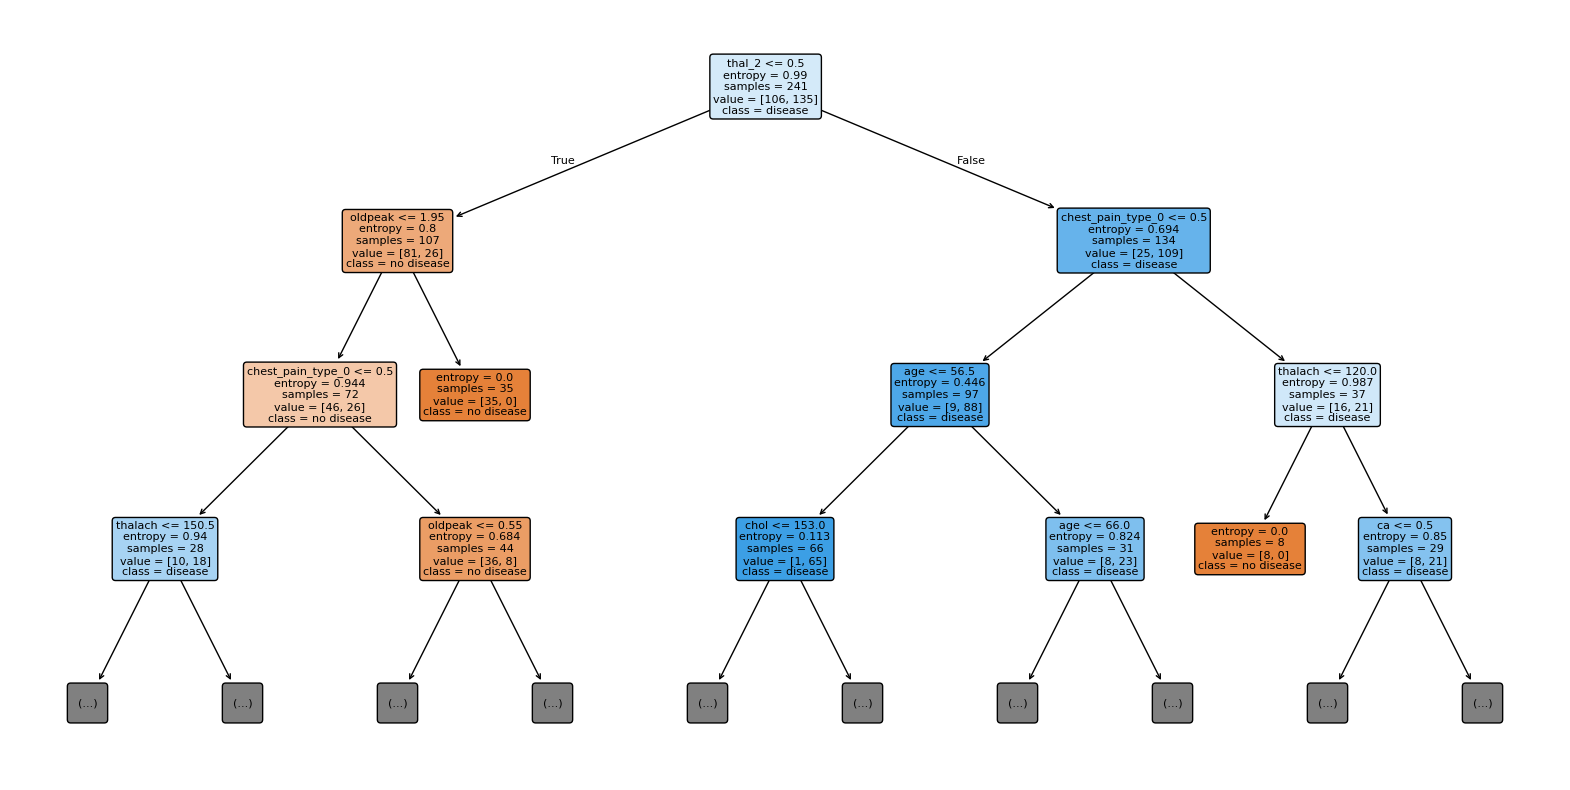

In [20]:
from sklearn.tree import plot_tree

# plotting the decision tree with entropy
plt.figure(figsize=(20, 10))
plot_tree(
    dtree_ent,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3, #if you want to see the entire tree, make it None, or change the number
    feature_names=X.columns,
    class_names=['no disease', 'disease']
)
plt.show()

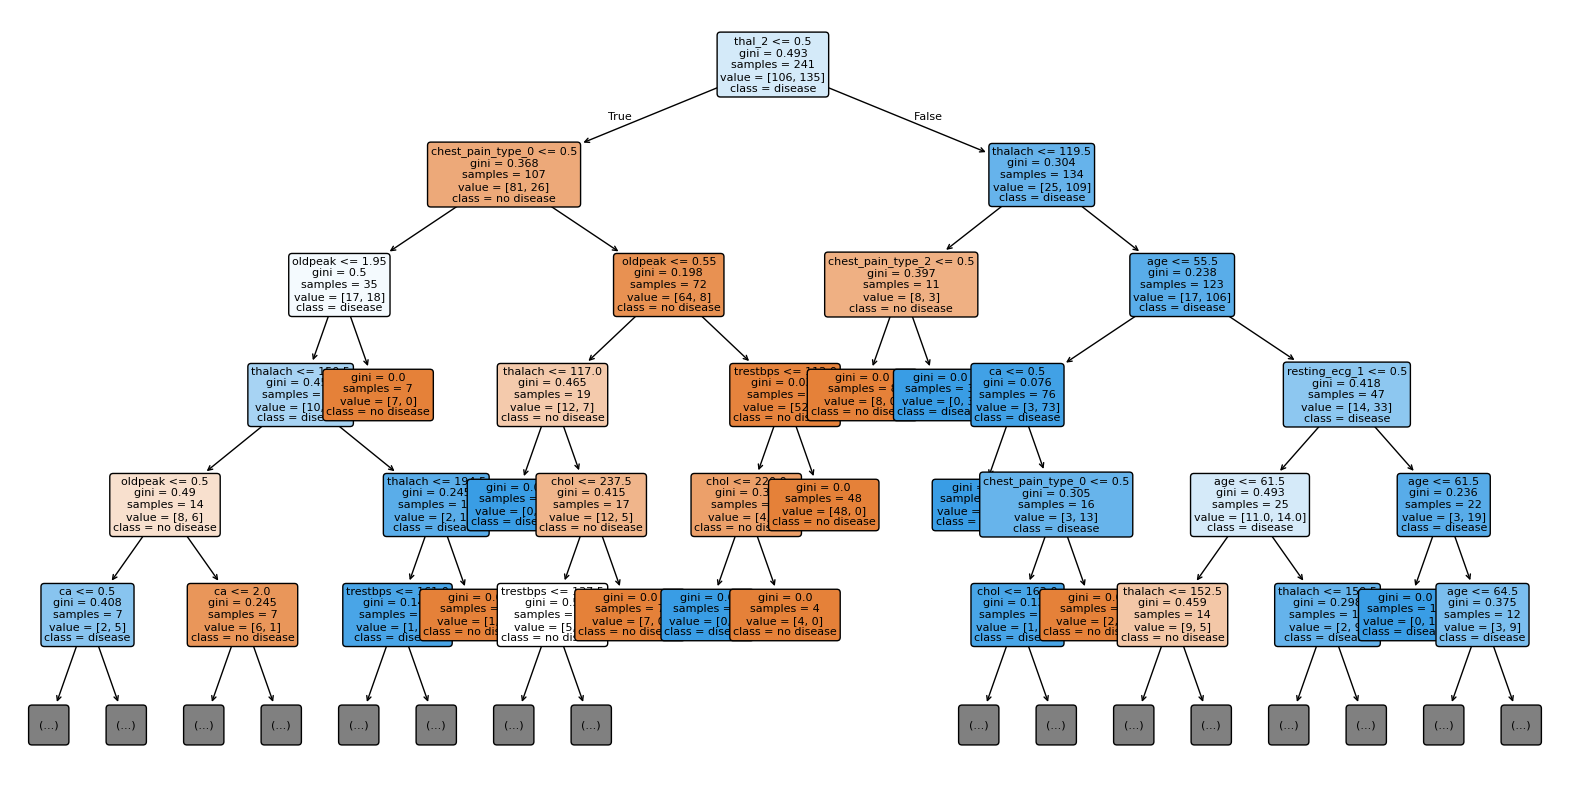

In [21]:
from sklearn.tree import plot_tree

# plotting the decision tree with gini
plt.figure(figsize=(20, 10))
plot_tree(
    dtree_gini,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth= 5 , #if you want to see the entire tree, make it None, or change the number
    feature_names=X.columns,
    class_names=['no disease', 'disease']
)
plt.show()

# pruning the decision tree

So now we have to teach the model when to stop splitting the nodes, and this is done by **pruning** the decision tree, by using the hyperparameters `max_depth`, `min_samples_split` 

### Best `Max_depth`  and `Min_samples_leaf` for our model
Lets see which max depth is the best for our model, we will use the accuracy score to evaluate the performance of the model. We will use a for loop to iterate through different values of max depth and plot the accuracy score for each value.

**its not manditory to study this code you should just learn the idea**

(you can try random numbers instead)

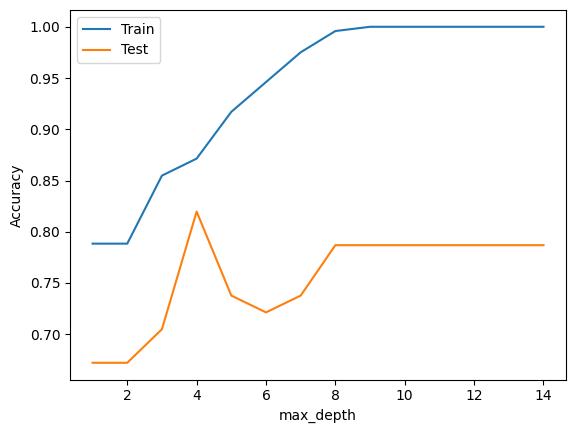

In [22]:
depths = range(1, 15)
train_scores, test_scores = [], []  # I made a list to store every accuracy score that we try 

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42 , criterion='entropy') # the d variable is an itterator it itterates from 1->15 (depth var)
    tree.fit(X_train, Y_train)      # I trained the model on the data
    train_scores.append(tree.score(X_train, Y_train)) # adding the values to the list
    test_scores.append(tree.score(X_test, Y_test))

plt.plot(depths, train_scores, label='Train') 
plt.plot(depths, test_scores, label='Test')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()

The best Accuracy for the test accuracy (the model accuracy) is at `max_depth = 4`

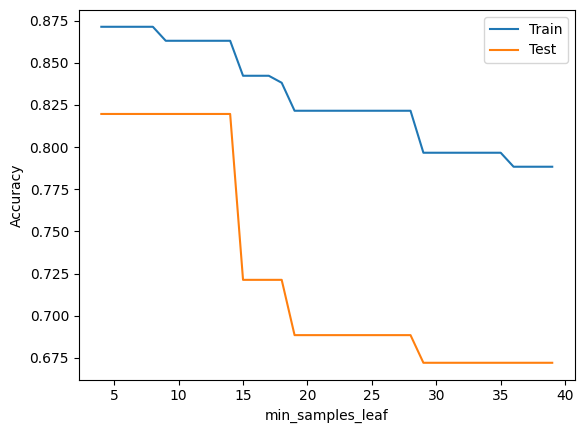

In [23]:
#using the same technique as with max_Depth
sample_split = range(4, 40)
trainScores_s, testScores_s = [], []

for s in sample_split:
    #since the graph above showed that 4 is the best max depth we used it for this tree
    sptree = DecisionTreeClassifier(min_samples_leaf=s, random_state=42, criterion='entropy', max_depth=4,) 
    sptree.fit(X_train, Y_train)
    trainScores_s.append(sptree.score(X_train, Y_train))
    testScores_s.append(sptree.score(X_test, Y_test))

plt.plot(sample_split, trainScores_s, label='Train')
plt.plot(sample_split, testScores_s, label='Test')
plt.xlabel('min_samples_leaf')
plt.ylabel('Accuracy')
plt.legend()

The best `minimum samples per leaf = 14` 

### pruned tree

I'll only do it for entropy since it has the best performance along from gini

In [24]:
Pruned_tree_ent = DecisionTreeClassifier(criterion= 'entropy', max_depth= 4 , min_samples_leaf= 14)
Pruned_tree_ent.fit(X_train, Y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",14
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [25]:
Train_score = Pruned_tree_ent.predict(X_train)
print('train accuracy score with criterion entropy after pruning index: {0:0.4f}'. format(accuracy_score(Y_train, Train_score)))

train accuracy score with criterion entropy after pruning index: 0.8631


In [26]:
Y_predict_pruned = Pruned_tree_ent.predict(X_test)
print('Model accuracy score with criterion entropy after pruning index: {0:0.4f}'. format(accuracy_score(Y_test, Y_predict_pruned)))

Model accuracy score with criterion entropy after pruning index: 0.8033


## Comparing the accuarcies before and after pruning

Before pruning : the training score was **0.1 ~ 100%** and the test score was **0.78 ~ 78%**, notice how the gap here is **22%**

after pruning : the training score was **0.863 ~ 86.3%** and the test score was **0.819 ~ 81.9%**, notice how the gap shrinked noticebly to **4.4%** !! 

**The lower the gap between the train accuracy and the test accuracy the better the model, it means its no longer overfitted**

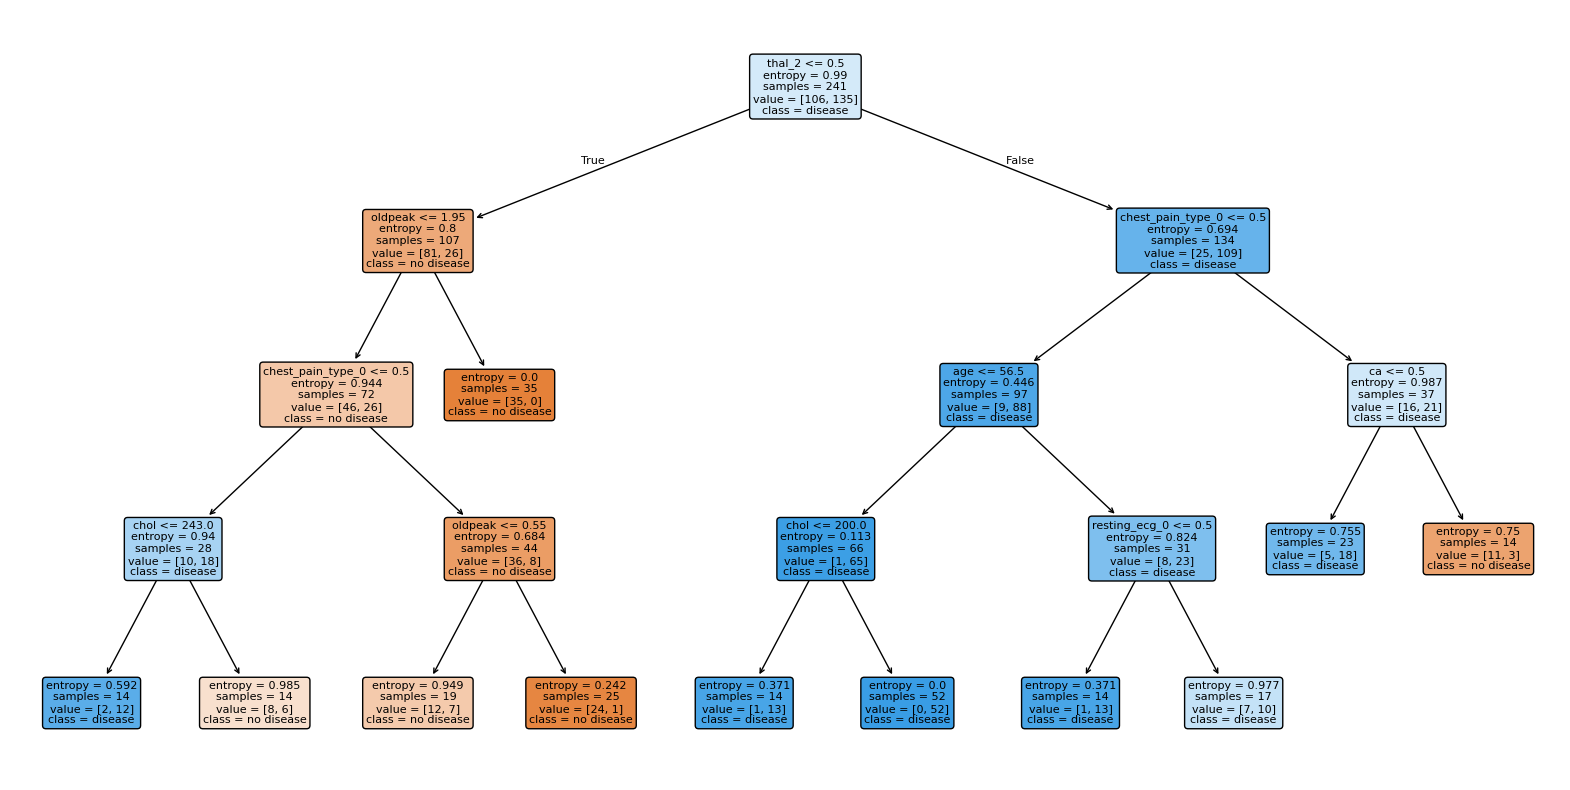

In [27]:
plt.figure(figsize=(20, 10))
plot_tree(
    Pruned_tree_ent,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=None, #if you want to see the entire tree, make it None, or change the number
    feature_names=X.columns,
    class_names=['no disease', 'disease']
)
plt.show()

Notice how the tree shrinked after pruning! 

# Bagging the decision tree

Imagine if we created a small tree *(a stump : a tree of only 2 leaves)* to help classify our patients, 

The small tree will perform so poorly since it's a lazy learner, but what if we created multiple different stumps ? 

Every stump chooses its own different threshold/decision boundry, every stump randomly selects a number of samples **from the orignial set of data** *(it can also choose one sample more than once)* and deals with the selected samples as their new customized set of data, which leaves us with entirely different stumps for each stump created, 
and eventually *every stump gets a vote on what the classification should be* 

think about it like this : is it better to ask one friend about their opinion? *or* ask all your friends for theirs?

so instead of using one tree that's a little more deep than a stump, we use multiple stumps to help us calssify!

Theres a model specifically for this using decison trees called `Random forest`

## Random forest

Best `max_depth`

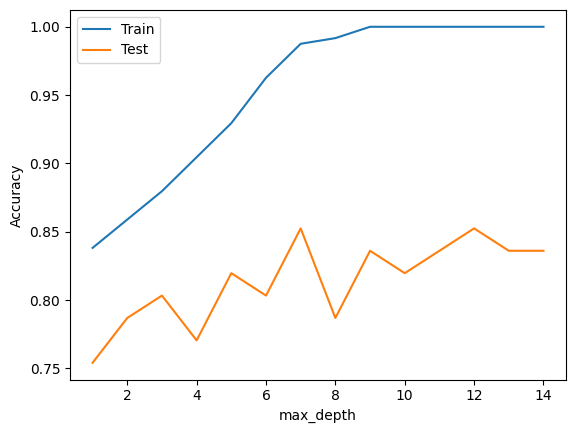

In [52]:
depths = range(1, 15)
train_scores, test_scores = [], []  # I made a list to store every accuracy score that we try 

for d in depths:
    forest = RandomForestClassifier(criterion='entropy', max_depth=d)
    forest.fit(X_train, Y_train)      # I trained the model on the data
    train_scores.append(forest.score(X_train, Y_train)) # adding the values to the list
    test_scores.append(forest.score(X_test, Y_test))

plt.plot(depths, train_scores, label='Train') 
plt.plot(depths, test_scores, label='Test')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()

best_index = test_scores.index(max(test_scores))
best_num = forest[best_index]
# print('The best depth = {0:0.4f}'.format(best_num))

Best `n_estimator` is the best number of trees\stumps the forest will have 

The best n_estimators = 108.0000


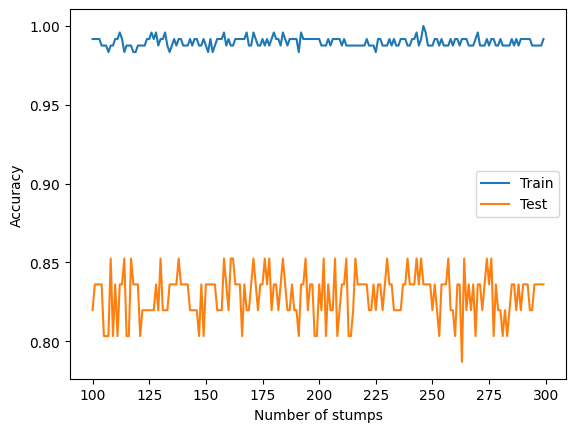

In [47]:
trees = range(100, 300)
train_scores, test_scores = [], []  # I made a list to store every accuracy score that we try 

for n in trees:
    forest = RandomForestClassifier(criterion='entropy', max_depth=7, n_estimators=n)
    forest.fit(X_train, Y_train)      # I trained the model on the data
    train_scores.append(forest.score(X_train, Y_train)) # adding the values to the list
    test_scores.append(forest.score(X_test, Y_test))

plt.plot(trees, train_scores, label='Train') 
plt.plot(trees, test_scores, label='Test')
plt.xlabel('Number of stumps')
plt.ylabel('Accuracy')
plt.legend()

best_index = test_scores.index(max(test_scores))
best_n_estimators = trees[best_index]
print('The best n_estimators = {0:0.4f}'.format(best_n_estimators))

In [48]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(criterion='entropy', max_depth=7 , n_estimators= 109)
rf.fit(X_train,Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",109
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [49]:
rf_trainScore = rf.predict(X_train)
print('train score : {0:0.4f}%'.format(accuracy_score(Y_train, rf_trainScore)*100))

train score : 98.3402%


In [50]:
rf_predict = rf.predict(X_test)
print('model accuracy : {0:0.4f}%'.format(accuracy_score(Y_test, rf_predict)*100))

model accuracy : 83.6066%


# boosting 

In [33]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import RandomizedSearchCV

In [34]:
param_dist = {
    "n_estimators": [100, 150, 200, 250, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2, 0.4, 0.5]
}
ada = AdaBoostClassifier(random_state=42)

search = RandomizedSearchCV(
    estimator=ada,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    random_state=42
)

search.fit(X_train, Y_train)

print("Best params:", search.best_params_)
print("Best CV score:", search.best_score_)

best_model = search.best_estimator_
print("Train accuracy:", accuracy_score(Y_train, best_model.predict(X_train)))
print("Test accuracy:", accuracy_score(Y_test, best_model.predict(X_test)))

Best params: {'n_estimators': 250, 'learning_rate': 0.01}
Best CV score: 0.825765306122449
Train accuracy: 0.8506224066390041
Test accuracy: 0.7868852459016393


In [35]:
# The model is already trained by RandomizedSearchCV; use the best estimator directly.
# This avoids using a manually selected parameter set that may be worse.

print("Best estimator:", best_model)

Best estimator: AdaBoostClassifier(learning_rate=0.01, n_estimators=250, random_state=42)


In [36]:
train_ada = best_model.predict(X_train)
print("Train accuracy:", accuracy_score(Y_train, train_ada))

Train accuracy: 0.8506224066390041


In [37]:
model_acc = best_model.predict(X_test)
print("Test accuracy:", accuracy_score(Y_test, model_acc))

Test accuracy: 0.7868852459016393
